<a href="https://colab.research.google.com/github/feliperib286/5-semestre-fatec/blob/main/projeto_maquinas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Treinando o conselho do Random Forest... Aguarde um instante.
Treinamento concluído! O Random Forest acertou 74.32% das previsões.

Relatório de Classificação Detalhado (Random Forest):
                            precision    recall  f1-score   support

              Sem ausência       1.00      0.89      0.94         9
      Falta médica parcial       0.61      0.63      0.62        49
Falta integral/afastamento       0.80      0.79      0.79        90

                  accuracy                           0.74       148
                 macro avg       0.80      0.77      0.78       148
              weighted avg       0.75      0.74      0.74       148


Arquivos 'modelo_absenteismo.pkl' e 'normalizador_absenteismo.pkl' salvos com sucesso!


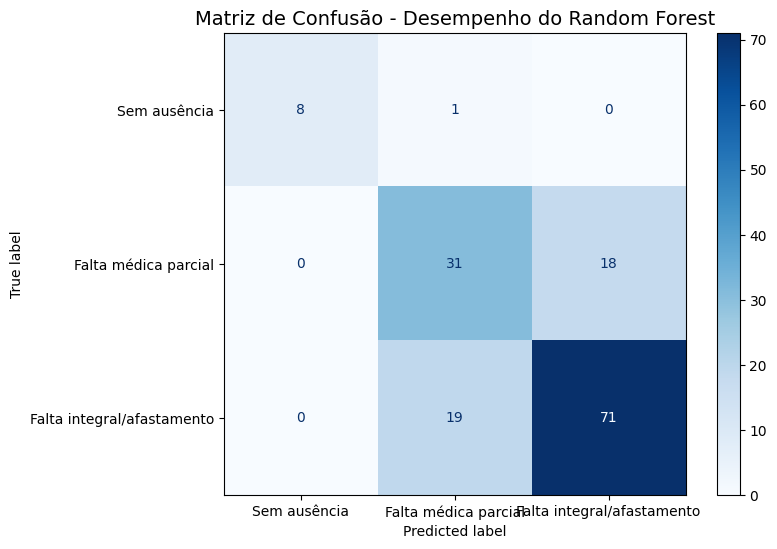


Treinando Rede Neural auxiliar para extração das curvas de validação...

Eficácia do Random Forest: 74.32%
Eficácia da Rede Neural: 63.51%


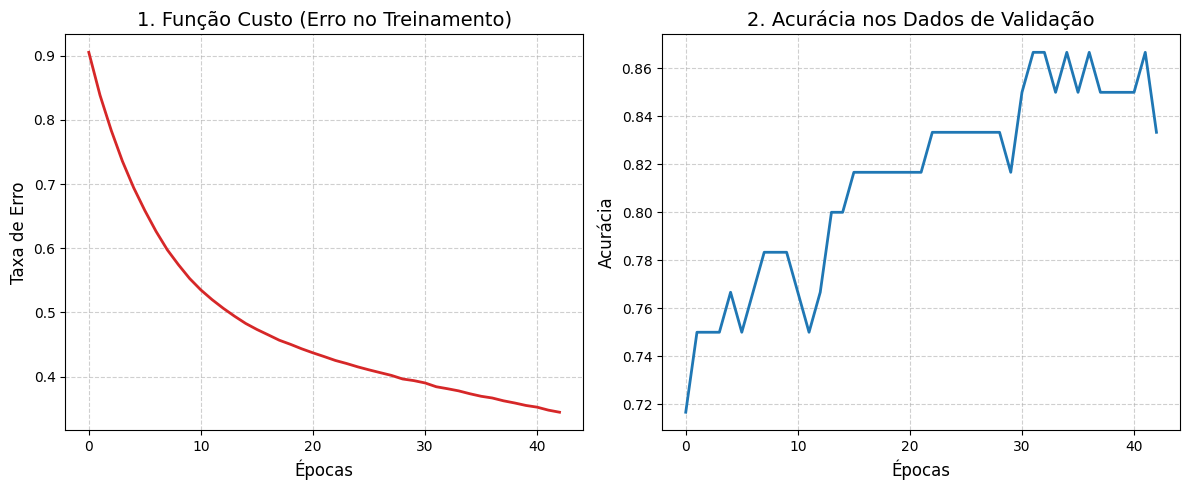


Relatório de Classificação Detalhado (Rede Neural):
                            precision    recall  f1-score   support

              Sem ausência       1.00      0.78      0.88         9
      Falta médica parcial       0.46      0.47      0.46        49
Falta integral/afastamento       0.70      0.71      0.71        90

                  accuracy                           0.64       148
                 macro avg       0.72      0.65      0.68       148
              weighted avg       0.64      0.64      0.64       148



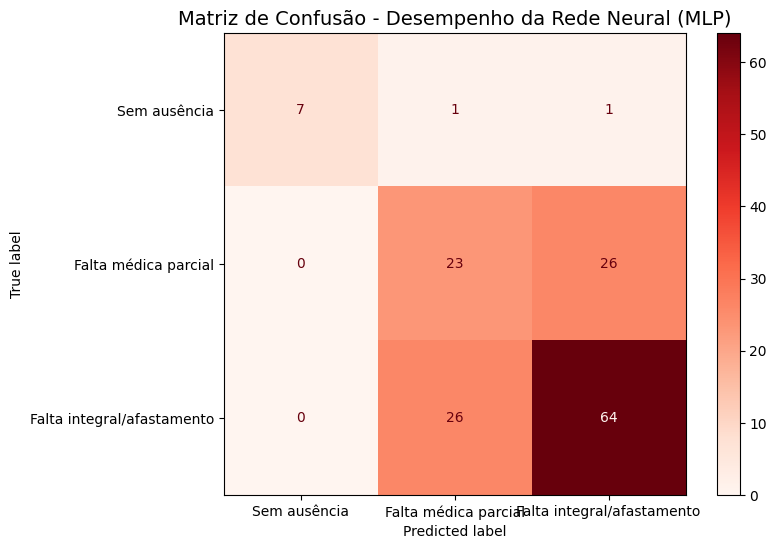


Top 5 Principais Motivos de Ausência na Empresa:


,Código,Quantidade de Faltas,Descrição do Motivo (CID/RH)
0,23,149,Consulta médica de rotina / Exame (RH)
1,28,112,Consulta dentária (RH)
2,27,69,Sessão de Fisioterapia (RH)
3,13,55,Doenças do sistema osteomuscular e tecido conj...
4,0,43,Sem motivo justificado / Não informado



--- TESTE AO VIVO: PREVISÃO DE FALTAS ---

Cenário A - O João ligou e avisou que vai ao DENTISTA (Código 28).
Previsão da Máquina: Categoria 1 - Falta médica parcial

Cenário B - O João ligou e avisou que tem DORES DE COSTAS (CID 13).
Previsão da Máquina: Categoria 2 - Falta integral/afastamento


In [ ]:
# ---------------------------------------------------------
# PASSO 1: IMPORTAR AS FERRAMENTAS NECESSÁRIAS
# ---------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# ---------------------------------------------------------
# PASSO 2: CARREGAR E TRATAR OS DADOS REAIS
# ---------------------------------------------------------
# O arquivo 'Absenteeism_at_work.csv' deve estar na mesma pasta do projeto
dados = pd.read_csv('Absenteeism_at_work.csv', sep=';')

# Função com a regra de negócio para classificar as ausências
def classificar_ausencia(horas):
    if horas == 0:
        return 0  # Sem ausência
    elif horas <= 2:
        return 1  # Falta médica parcial
    else:
        return 2  # Falta integral / afastamento

# Criando a nova coluna 'Categoria_Alvo' aplicando a regra acima
dados['Categoria_Alvo'] = dados['Absenteeism time in hours'].apply(classificar_ausencia)

# Excluir a coluna antiga de horas para evitar vazamento de dados
dados = dados.drop(columns=['Absenteeism time in hours'])

# ---------------------------------------------------------
# PASSO 3: SEPARAR "PERGUNTAS" (X) DAS "RESPOSTAS" (y)
# ---------------------------------------------------------
y = dados['Categoria_Alvo']
X = dados.drop(columns=['Categoria_Alvo'])

# ---------------------------------------------------------
# PASSO 4: DIVIDIR ENTRE TREINO E TESTE
# ---------------------------------------------------------
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# ---------------------------------------------------------
# PASSO 5: NORMALIZAÇÃO DOS DADOS
# ---------------------------------------------------------
normalizador = StandardScaler()
X_treino_normalizado = normalizador.fit_transform(X_treino)
X_teste_normalizado = normalizador.transform(X_teste)

# ---------------------------------------------------------
# PASSO 6: CRIAR E TREINAR O RANDOM FOREST (Modelo Principal)
# ---------------------------------------------------------
modelo_floresta = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

print("Treinando o conselho do Random Forest... Aguarde um instante.")
modelo_floresta.fit(X_treino_normalizado, y_treino)

# ---------------------------------------------------------
# PASSO 7: TESTAR E AVALIAR O DESEMPENHO DO RANDOM FOREST
# ---------------------------------------------------------
previsoes = modelo_floresta.predict(X_teste_normalizado)
acuracia = accuracy_score(y_teste, previsoes)

print(f"Treinamento concluído! O Random Forest acertou {acuracia * 100:.2f}% das previsões.")

nomes_classes = ['Sem ausência', 'Falta médica parcial', 'Falta integral/afastamento']
print("\nRelatório de Classificação Detalhado (Random Forest):")
print(classification_report(y_teste, previsoes, target_names=nomes_classes))


# PASSO 8: GRÁFICO DA MATRIZ DE CONFUSÃO (Random Forest)
# ---------------------------------------------------------
matriz = confusion_matrix(y_teste, previsoes)
fig, ax = plt.subplots(figsize=(8, 6))
display_matriz = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=nomes_classes)
display_matriz.plot(cmap='Blues', ax=ax)
plt.title('Matriz de Confusão - Desempenho do Random Forest', fontsize=14)
plt.show()

# ---------------------------------------------------------
# PASSO 09: EXTRAÇÃO DE CURVAS E TREINO DA REDE NEURAL (MLP)
# ---------------------------------------------------------
print("\nTreinando Rede Neural auxiliar para extração das curvas de validação...")
rede_neural = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    max_iter=2000,
    activation='relu',
    alpha=0.05,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)
rede_neural.fit(X_treino_normalizado, y_treino)

# Avaliar a eficácia exata da Rede Neural nos dados de teste
previsoes_rn = rede_neural.predict(X_teste_normalizado)
acuracia_rn = accuracy_score(y_teste, previsoes_rn)

print(f"\nEficácia do Random Forest: {acuracia * 100:.2f}%")
print(f"Eficácia da Rede Neural: {acuracia_rn * 100:.2f}%")

# Desenhando as curvas de aprendizado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: A curva de Custo
ax1.plot(rede_neural.loss_curve_, color='tab:red', linewidth=2)
ax1.set_title('1. Função Custo (Erro no Treinamento)', fontsize=14)
ax1.set_xlabel('Épocas', fontsize=12)
ax1.set_ylabel('Taxa de Erro', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)

# Gráfico 2: A curva de Validação
ax2.plot(rede_neural.validation_scores_, color='tab:blue', linewidth=2)
ax2.set_title('2. Acurácia nos Dados de Validação', fontsize=14)
ax2.set_xlabel('Épocas', fontsize=12)
ax2.set_ylabel('Acurácia', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# PASSO 9.1: RELATÓRIO E MATRIZ DA REDE NEURAL
# ---------------------------------------------------------
print("\nRelatório de Classificação Detalhado (Rede Neural):")
print(classification_report(y_teste, previsoes_rn, target_names=nomes_classes))

matriz_rn = confusion_matrix(y_teste, previsoes_rn)
fig, ax = plt.subplots(figsize=(8, 6))
display_matriz_rn = ConfusionMatrixDisplay(confusion_matrix=matriz_rn, display_labels=nomes_classes)
display_matriz_rn.plot(cmap='Reds', ax=ax)
plt.title('Matriz de Confusão - Desempenho da Rede Neural (MLP)', fontsize=14)
plt.show()

# ---------------------------------------------------------
# PASSO 10: ANÁLISE DOS MOTIVOS REAIS (Visão de Negócio)
# ---------------------------------------------------------
dicionario_motivos = {
    0: 'Sem motivo justificado / Não informado',
    1: 'Doenças infecciosas e parasitárias (CID-10)',
    2: 'Neoplasias / Tumores (CID-10)',
    3: 'Doenças do sangue e órgãos hematopoiéticos (CID-10)',
    4: 'Doenças endócrinas, nutricionais e metabólicas (CID-10)',
    5: 'Transtornos mentais e comportamentais (CID-10)',
    6: 'Doenças do sistema nervoso (CID-10)',
    7: 'Doenças do olho e anexos (CID-10)',
    8: 'Doenças do ouvido e apófise mastoide (CID-10)',
    9: 'Doenças do aparelho cardiovascular (CID-10)',
    10: 'Doenças do aparelho respiratório (CID-10)',
    11: 'Doenças do aparelho digestivo (CID-10)',
    12: 'Doenças da pele e tecido subcutâneo (CID-10)',
    13: 'Doenças do sistema osteomuscular e tecido conjuntivo (CID-10)',
    14: 'Doenças do aparelho geniturinário (CID-10)',
    15: 'Gravidez, parto e puerpério (CID-10)',
    16: 'Afecções originadas no período perinatal (CID-10)',
    17: 'Malformações congênitas e anomalias cromossómicas (CID-10)',
    18: 'Sintomas, sinais e achados anormais em exames (CID-10)',
    19: 'Lesões, envenenamentos e consequências de causas externas (CID-10)',
    20: 'Causas externas de morbidade e mortalidade (CID-10)',
    21: 'Fatores que influenciam o estado de saúde (CID-10)',
    22: 'Acompanhamento de familiar/paciente (RH)',
    23: 'Consulta médica de rotina / Exame (RH)',
    24: 'Doação de sangue (RH)',
    25: 'Exame de laboratório (RH)',
    26: 'Falta injustificada (RH)',
    27: 'Sessão de Fisioterapia (RH)',
    28: 'Consulta dentária (RH)'
}

top_motivos = dados['Reason for absence'].value_counts().head(5).reset_index()
top_motivos.columns = ['Código', 'Quantidade de Faltas']
top_motivos['Descrição do Motivo (CID/RH)'] = top_motivos['Código'].map(dicionario_motivos)

print("\nTop 5 Principais Motivos de Ausência na Empresa:")
display(top_motivos)

# ---------------------------------------------------------
# PASSO 11: TESTE AO VIVO PARA A BANCA (Simulação)
# ---------------------------------------------------------
# 1. Criamos um funcionário com a MÉDIA EXATA da empresa em todas as colunas
funcionario_ficticio = pd.DataFrame([X_treino.mean()])

# 2. Ajustamos apenas o perfil básico do "João" para não haver ruídos
funcionario_ficticio['Age'] = 30
funcionario_ficticio['Distance from Residence to Work'] = 15
funcionario_ficticio['Son'] = 1
funcionario_ficticio['Disciplinary failure'] = 0

print("\n--- TESTE AO VIVO: PREVISÃO DE FALTAS ---")

# ==========================================
# CENÁRIO A: João vai ao Dentista (Motivo 28)
# ==========================================
funcionario_ficticio['Reason for absence'] = 28

# Normalizamos a ficha do João
joao_normalizado_A = normalizador.transform(funcionario_ficticio)
previsao_A = modelo_floresta.predict(joao_normalizado_A)[0]

print(f"\nCenário A - O João ligou e avisou que vai ao DENTISTA (Código 28).")
print(f"Previsão da Máquina: Categoria {previsao_A} - {nomes_classes[previsao_A]}")

# ==========================================
# CENÁRIO B: João está com Dor de Costas (Motivo 13)
# ==========================================
funcionario_ficticio['Reason for absence'] = 13

# Normalizamos novamente com a nova doença
joao_normalizado_B = normalizador.transform(funcionario_ficticio)
previsao_B = modelo_floresta.predict(joao_normalizado_B)[0]

print(f"\nCenário B - O João ligou e avisou que tem DORES DE COSTAS (CID 13).")
print(f"Previsão da Máquina: Categoria {previsao_B} - {nomes_classes[previsao_B]}")